<div style="font-family: 'Montserrat', sans-serif; border-left: 6px solid #E94E1B; padding: 8px 16px;">
<h1 style="color:#312783; margin:0;">EDA del corpus consolidado</h1>
<p style="color:#5A2673; margin:4px 0 0 0;">Detección y análisis lingüístico de contenido censurado en redes sociales chinas</p>
<p style="margin:4px 0 0 0;">Munive Ramírez Ibrahim</p>
<p style="margin:4px 0 0 0;">Esteva Gallegos Carlos Fabián</p>
</div>

Entrada: `corpus_zh.csv`, salida de `unir_csv.py`. Las etiquetas son `censored` / `uncensored`, las del nombre de archivo.

In [1]:
import re
import jieba
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter

jieba.setLogLevel(60)

azul, naranja, morado = '#312783', '#E94E1B', '#5A2673'
col = {'censored': 'lightcoral', 'uncensored': 'lightgreen'}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

/home/ibra/venv_ds/lib/python3.10/site-packages/jieba/_compat.py:18: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


## Carga y verificación

In [2]:
df = pd.read_csv('corpus_zh.csv', dtype={'texto_original': str, 'texto_zh': str, 'etiqueta': str,
                                         'tema': str, 'categoria': str, 'archivo': str})
print(df.shape)
print(df.dtypes)
print('Nulos:\n', df.isna().sum())
print('Etiquetas:', df['etiqueta'].unique())
df.sample(5)

(2131, 9)
texto_original    object
texto_zh          object
label              int64
etiqueta          object
tema              object
categoria         object
archivo           object
tiene_zw            bool
longitud           int64
dtype: object
Nulos:
 texto_original    0
texto_zh          0
label             0
etiqueta          0
tema              0
categoria         0
archivo           0
tiene_zw          0
longitud          0
dtype: int64
Etiquetas: ['censored' 'uncensored']


,texto_original,texto_zh,label,etiqueta,tema,categoria,archivo,tiene_zw,longitud
1438,如果说携程那起事件让国人愤怒不已的话，毫无疑问，红黄蓝幼儿园这起涉嫌虐童的恶劣事件已经让中产...,如果说携程那起事件让国人愤怒不已的话，毫无疑问，红黄蓝幼儿园这起涉嫌虐童的恶劣事件已经让中产...,1,censored,kindergarten,abuso en guarderías,kindergarten-censored.csv,False,98
1857,陈忆 打仗靠张召忠，养老靠戴相龙。破案靠聂海芬，防疫靠板蓝根。慈 善靠郭美美，幸福靠CCTV...,陈忆 打仗靠张召忠，养老靠戴相龙。破案靠聂海芬，防疫靠板蓝根。慈 善靠郭美美，幸福靠CCTV...,1,censored,smog,contaminación e inocuidad alimentaria,smog-censored.csv,False,141
274,那一定是大google屏蔽了中国！,那一定是大google屏蔽了中国！,1,censored,censored,censura y propaganda en internet,censored-censored.csv,False,17
1598,取地沟油四钱，三聚氰胺二钱，苏丹红三钱，甲醛少许，以雾霾为引子，用腌过的死猪肉泡温水煎服，可...,取地沟油四钱，三聚氰胺二钱，苏丹红三钱，甲醛少许，以雾霾为引子，用腌过的死猪肉泡温水煎服，可...,0,uncensored,melamine,contaminación e inocuidad alimentaria,melamine-uncensored.csv,True,59
828,有些事情，当事人什么都不知道，为什么你能说得像是亲力亲为一样。我想我等穷尽毕生，也只是个地沟...,有些事情，当事人什么都不知道，为什么你能说得像是亲力亲为一样。我想我等穷尽毕生，也只是个地沟...,0,uncensored,ditch-oil,contaminación e inocuidad alimentaria,ditch-oil-uncensored.csv,False,71


## Tamaño y balance de clases

Total: 2131 | censored: 999 (46.9 %)


etiqueta,censored,uncensored,total,% censored
tema,,,,
boxilai,125.0,75.0,200.0,62.5
censored,193.0,215.0,408.0,47.3
ditch-oil,119.0,136.0,255.0,46.7
fifty-cent,253.0,290.0,543.0,46.6
kindergarten,53.0,93.0,146.0,36.3
melamine,17.0,37.0,54.0,31.5
poisonous-milk-powder,21.0,47.0,68.0,30.9
smog,218.0,239.0,457.0,47.7
TOTAL,999.0,1132.0,2131.0,46.9


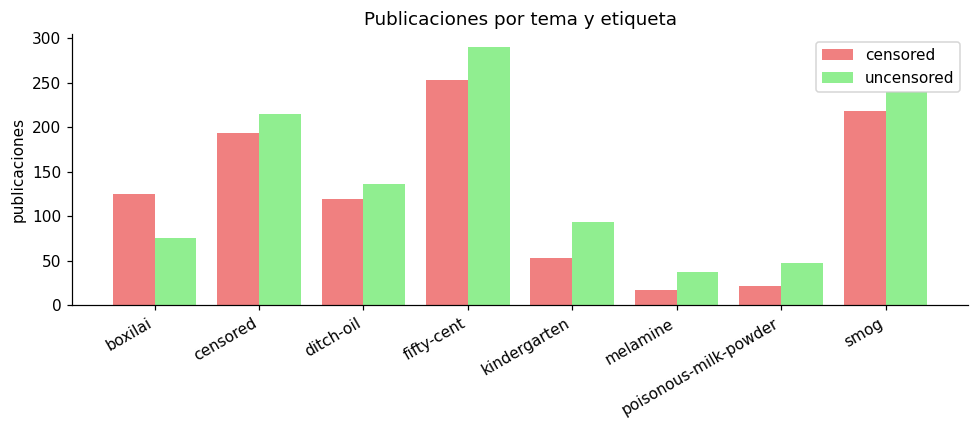

In [ ]:
print('Total:', len(df), '| censored:', (df.label == 1).sum(),
      f'({(df.label == 1).mean() * 100:.1f} %)')

tab = df.pivot_table(index='tema', columns='etiqueta', values='texto_zh', aggfunc='count', fill_value=0)
tab['total'] = tab.sum(axis=1)
tab['% censored'] = (tab['censored'] / tab['total'] * 100).round(1)
tab.loc['TOTAL'] = [tab['censored'].sum(), tab['uncensored'].sum(), tab['total'].sum(),
                    round(tab['censored'].sum() / tab['total'].sum() * 100, 1)]
display(tab)

t = tab.drop('TOTAL')
x = np.arange(len(t)); w = 0.4
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x - w/2, t['censored'], w, color=col['censored'], label='censored')
ax.bar(x + w/2, t['uncensored'], w, color=col['uncensored'], label='uncensored')
ax.set_xticks(x)
ax.set_xticklabels(t.index, rotation=30, ha='right')
ax.set_ylabel('publicaciones')
ax.set_title('Publicaciones por tema y etiqueta'); ax.legend()
plt.tight_layout()
plt.show()

## Verificación contra la tabla de conteos de Ng et al.

Los conteos son de la Tabla 1 cruda del artículo. Tras depurar pueden faltar algunas publicaciones (duplicados y contradicciones).

In [4]:
tabla1 = pd.DataFrame(
    {'artículo_censored': [223, 120, 49, 195, 258, 125, 53],
     'artículo_uncensored': [240, 138, 85, 216, 290, 75, 94]},
    index=['smog', 'ditch-oil', 'milk-scandal', 'censored', 'fifty-cent', 'boxilai', 'kindergarten'])

g = df.assign(grupo=df['tema'].replace({'melamine': 'milk-scandal',
                                        'poisonous-milk-powder': 'milk-scandal'}))
conteo = g.pivot_table(index='grupo', columns='etiqueta', values='texto_zh',
                       aggfunc='count', fill_value=0).rename(columns=lambda c: f'CSV_{c}')

cmp = tabla1.join(conteo, how='left').fillna(0).astype(int)
cmp['dif. censored'] = cmp['CSV_censored'] - cmp['artículo_censored']
cmp['dif. uncensored'] = cmp['CSV_uncensored'] - cmp['artículo_uncensored']
display(cmp)

,artículo_censored,artículo_uncensored,CSV_censored,CSV_uncensored,dif. censored,dif. uncensored
smog,223,240,218,239,-5,-1
ditch-oil,120,138,119,136,-1,-2
milk-scandal,49,85,38,84,-11,-1
censored,195,216,193,215,-2,-1
fifty-cent,258,290,253,290,-5,0
boxilai,125,75,125,75,0,0
kindergarten,53,94,53,93,0,-1


## Detección de caracteres invisibles

Este análisis no busca un carácter concreto. Revisa todos los caracteres del texto crudo y ordena los que más difieren entre clases. El carácter problemático debe salir del propio proceso.

1. **Escaneo sin supuestos.** Se listan todos los caracteres distintos del texto original, excepto letras y dígitos (categorías Unicode `L*` y `N*`), que se revisaron en la sección de limpieza.
2. **Presencia por clase.** Para cada carácter se calcula el porcentaje de publicaciones censuradas y no censuradas que lo contienen.
3. **Ordenar por diferencia.** Se ordena por la diferencia absoluta entre clases, en puntos porcentuales. Un carácter que aparece en muchas publicaciones de una clase y casi nada en la otra no depende del contenido, sino de la captura.
4. **Inspeccionar con `repr`.** Un carácter invisible no se ve en pantalla. Se muestra su representación para confirmar de qué carácter se trata.

In [5]:
import unicodedata

def escanear_caracteres(textos_por_clase):
    """Presencia (%) de cada carácter no alfanumérico por clase, ordenada por diferencia entre clases."""
    vocab = set()
    for textos in textos_por_clase.values():
        vocab |= set(''.join(textos))
    vocab = {c for c in vocab if unicodedata.category(c)[0] not in 'LN'}

    filas = []
    for c in vocab:
        fila = {'carácter': repr(c), 'código': f'U+{ord(c):04X}',
                'categoría': unicodedata.category(c), 'nombre': unicodedata.name(c, '?')}
        for e, textos in textos_por_clase.items():
            fila[f'% {e}'] = round(textos.str.contains(c, regex=False).mean() * 100, 2)
        filas.append(fila)

    out = pd.DataFrame(filas)
    out['diferencia (pp)'] = (out['% censored'] - out['% uncensored']).abs().round(2)
    return out.sort_values('diferencia (pp)', ascending=False).reset_index(drop=True)

textos_crudos = {e: df.loc[df.etiqueta == e, 'texto_original'].fillna('')
                 for e in ['censored', 'uncensored']}
escaneo = escanear_caracteres(textos_crudos)
display(escaneo.head(15))

,carácter,código,categoría,nombre,% censored,% uncensored,diferencia (pp)
0,'\u200b',U+200B,Cf,ZERO WIDTH SPACE,2.20,60.42,58.22
1,' ',U+0020,Zs,SPACE,25.33,73.41,48.08
2,'。',U+3002,Po,IDEOGRAPHIC FULL STOP,71.07,56.45,14.62
3,'，',U+FF0C,Po,FULLWIDTH COMMA,89.39,80.57,8.82
4,'：',U+FF1A,Po,FULLWIDTH COLON,16.72,8.22,8.50
5,'？',U+FF1F,Po,FULLWIDTH QUESTION MARK,29.83,23.76,6.07
6,'、',U+3001,Po,IDEOGRAPHIC COMMA,22.02,16.17,5.85
7,'；',U+FF1B,Po,FULLWIDTH SEMICOLON,10.01,4.42,5.59
8,'”',U+201D,Pf,RIGHT DOUBLE QUOTATION MARK,17.42,13.07,4.35
9,'“',U+201C,Pi,LEFT DOUBLE QUOTATION MARK,17.32,13.43,3.89


In [6]:
# Inspección del carácter con mayor diferencia entre clases
top = escaneo.iloc[0]
print('Carácter con mayor diferencia:', top['código'], top['nombre'],
      f"| censored {top['% censored']} % vs uncensored {top['% uncensored']} %")

caracter = chr(int(top['código'][2:], 16))
ejemplos = df.loc[df['texto_original'].fillna('').str.contains(caracter, regex=False), 'texto_original']
for t in ejemplos.head(3):
    print(repr(t[:60]))

Carácter con mayor diferencia: U+200B ZERO WIDTH SPACE | censored 2.2 % vs uncensored 60.42 %
'怪不得第一次听薄熙来名字的时候感觉熟悉又陌生 原来是希伯来人作怪 \u200b'
'大连肃清薄熙来流毒。 \u200b'
'看了下，几乎关于L U WE I事件的所有微博，或原文被屏蔽，或评论都被关闭了，转发也受限制。谁干的？某权力部门还是新浪'


## Limpieza y sesgos de captura

Se revisa qué rasgos superficiales siguen presentes tras la limpieza, y cuántas publicaciones traían `\u200b`.

In [7]:
pat = {'URL': r'https?://|www\.', 'mención @': r'@\S', 'latinas': r'[A-Za-z]', 'dígitos': r'\d'}
sup = pd.DataFrame({k: df['texto_zh'].str.contains(v, regex=True).groupby(df['etiqueta']).mean() * 100
                    for k, v in pat.items()}).round(1).T
sup.columns.name = '% de publicaciones con...'
display(sup)

zw = df.groupby('etiqueta')['tiene_zw'].agg(['sum', 'count'])
zw['%'] = (zw['sum'] / zw['count'] * 100).round(1)
print('Publicaciones que traían \\u200b (antes de limpiar):')
display(zw)

% de publicaciones con...,censored,uncensored
URL,0.0,0.0
mención @,0.0,0.0
latinas,13.2,12.1
dígitos,18.6,18.9


Publicaciones que traían \u200b (antes de limpiar):


,sum,count,%
etiqueta,,,
censored,22,999,2.2
uncensored,684,1132,60.4


## Longitud

Sesgo conocido del corpus: las censuradas son más cortas. Se compara la distribución y la mediana por tema.

,count,mean,std,min,50%,90%,99%,max
etiqueta,,,,,,,,
censored,999.0,91.3,42.7,5.0,100.0,140.0,147.0,161.0
uncensored,1132.0,85.6,70.1,5.0,71.0,150.0,332.5,637.0


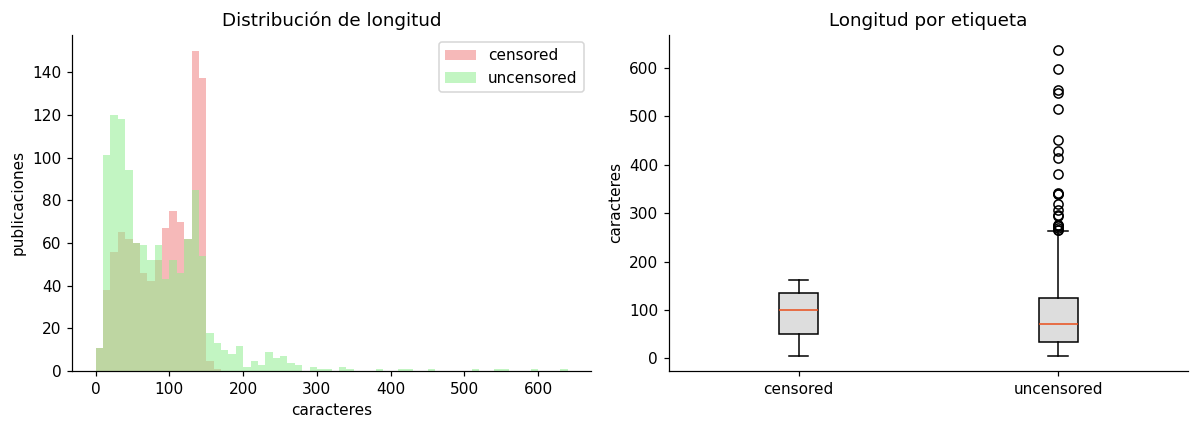

etiqueta,censored,uncensored
tema,,
boxilai,98.0,122.0
censored,83.0,44.0
ditch-oil,114.0,75.5
fifty-cent,85.0,79.0
kindergarten,111.0,139.0
melamine,134.0,88.0
poisonous-milk-powder,134.0,85.0
smog,108.0,49.0


In [ ]:
display(df.groupby('etiqueta')['longitud'].describe(percentiles=[.5, .9, .99]).round(1))

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
bins = np.arange(0, df['longitud'].max() + 10, 10)

for e in ['censored', 'uncensored']:

    axs[0].hist(df.loc[df.etiqueta == e, 'longitud'], bins=bins, alpha=.55, color=col[e], label=e)

axs[0].set_xlabel('caracteres'); axs[0].set_ylabel('publicaciones'); axs[0].legend()
axs[0].set_title('Distribución de longitud')
axs[1].boxplot([df.loc[df.etiqueta == e, 'longitud'] for e in ['censored', 'uncensored']],
               patch_artist=True, boxprops=dict(facecolor='#ddd'), medianprops=dict(color=naranja))

axs[1].set_xticks([1, 2]); axs[1].set_xticklabels(['censored', 'uncensored'])
axs[1].set_ylabel('caracteres'); axs[1].set_title('Longitud por etiqueta')
plt.tight_layout()
plt.show()

med = df.pivot_table(index='tema', columns='etiqueta', values='longitud', aggfunc='median')
display(med.round(1))

## Palabras más frecuentes por clase

Conteo de frecuencias de palabras de dos o más caracteres chinos, segmentadas con jieba.

In [ ]:
han = re.compile(r'^[\u4e00-\u9fff]{2,}$')
df['tokens'] = df['texto_zh'].apply(lambda s: [t for t in jieba.lcut(s) if han.match(t)])

cnt = {e: Counter(t for toks in df.loc[df.etiqueta == e, 'tokens'] for t in toks)
       for e in ['censored', 'uncensored']}

print('Tokens por clase:', {e: sum(c.values()) for e, c in cnt.items()})
print('Vocabulario por clase:', {e: len(c) for e, c in cnt.items()})

top = pd.DataFrame({e: [f'{w} ({n})' for w, n in cnt[e].most_common(20)] for e in cnt})
display(top)

Tokens por clase: {'censored': 27978, 'uncensored': 29775}
Vocabulario por clase: {'censored': 10189, 'uncensored': 10417}


,censored,uncensored
0,五毛 (331),五毛 (341)
1,屏蔽 (209),屏蔽 (222)
2,一个 (191),新浪 (211)
3,中国 (187),地沟油 (180)
4,薄熙来 (177),一个 (167)
5,没有 (154),我们 (164)
6,地沟油 (145),中国 (160)
7,不是 (122),红黄蓝 (157)
8,就是 (118),没有 (155)
9,我们 (117),幼儿园 (146)
